# Prospective Power Analysis

## Executive Summary

This notebook answers a planning question: how much traffic would a future two-group experiment need to detect a worthwhile change in conversion rate?

The target is 80% statistical power. In plain language, if the specified improvement is real and all model assumptions hold, a study of the planned size should detect it about 80% of the time. This does not mean there is an 80% chance that a result is true.

Historical traffic is used only to estimate planning capacity. The source data is monthly, so the 30/60/90/120/180-day views are future scenarios—not reconstructed daily observations.

## Planning Question and Method

The planned outcome is click-to-conversion rate. The calculation assumes two equally sized, independent groups: control and treatment.

Statistical power is the chance that a test will detect a specified effect when that effect is genuinely present. The minimum detectable effect (MDE) is the smallest conversion-rate gap that a design of a given size is expected to detect reliably. Smaller effects require more traffic.

The normal approximation estimates sample size for target relative lifts and MDE for fixed traffic windows. A live design would still need adjustments for auction constraints, repeated users, seasonality, attribution lag, traffic loss and an uneven split between groups.

**H₀:** future treatment and control conversion rates are equal.

**H₁:** they differ.

**Target power:** 80%. **Two-sided α:** 0.05. **Allocation:** 50/50.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import norm

for candidate in [Path.cwd(), *Path.cwd().parents]:
    if (candidate / "src" / "marketing_analysis.py").exists():
        PROJECT_ROOT = candidate
        break
else:
    raise FileNotFoundError("Run from the repository root or notebooks directory.")
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from marketing_analysis import prepare_data, aggregate_performance

DATA_PATH = PROJECT_ROOT / "data" / "shopping_mall_paid_search.csv"
OUTPUT_DIR = PROJECT_ROOT / "outputs"; OUTPUT_DIR.mkdir(exist_ok=True)
df = prepare_data(DATA_PATH)
overall = aggregate_performance(df.assign(portfolio="All"), "portfolio").iloc[0]
BASELINE_RATE = overall["conversion_rate"]
BASE_CPA = overall["cpa"]
HISTORICAL_DAYS = 153  # July 1 through November 30, 2021
CLICKS_PER_CALENDAR_DAY = overall["clicks"] / HISTORICAL_DAYS
RNG_SEED = 42
ALPHA = 0.05; POWER = 0.80
Z_ALPHA = norm.ppf(1-ALPHA/2); Z_POWER = norm.ppf(POWER)
print(f"Historical baseline conversion rate: {BASELINE_RATE:.3%}")
print(f"Historical aggregate CPA: ${BASE_CPA:.2f}")
print(f"Observed aggregate clicks / 153 calendar days: {CLICKS_PER_CALENDAR_DAY:,.1f}")

Historical baseline conversion rate: 10.384%
Historical aggregate CPA: $6.62
Observed aggregate clicks / 153 calendar days: 6,042.5


## Required Empirical Power Analysis for CPA

The simulation asks how often an independent t-test would detect a true CPA difference under the lab assumptions. Channel A is centered on the historical CPA. Channel B is 5%, 10%, 15% or 20% higher. Both use a standard deviation equal to 15% of base CPA, with simulated values floored at 50% of base CPA.

effect_size_pct,5,10,15,20
n_days,,,,
30,0.242,0.725,0.971,0.999
60,0.426,0.945,0.998,1.000
90,0.612,0.993,1.000,1.000
120,0.724,1.000,1.000,1.000
180,0.886,1.000,1.000,1.000


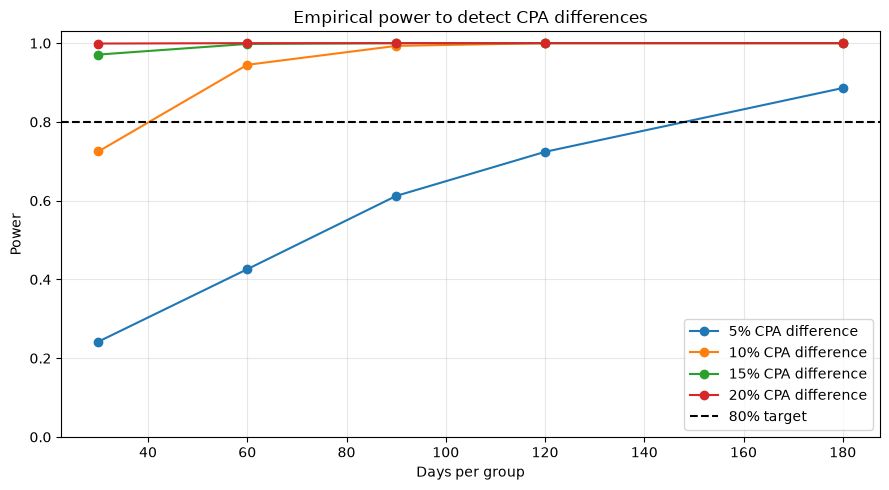

In [2]:
def empirical_power_cpa(true_diff_pct, base_cpa, n_days, n_sim=1000, alpha=0.05):
    seed = RNG_SEED + int(round(true_diff_pct * 10_000)) * 1_000 + int(n_days)
    rng = np.random.default_rng(seed)
    standard_deviation = base_cpa * 0.15
    minimum_cpa = base_cpa * 0.50
    significant_results = 0
    for _ in range(n_sim):
        channel_a = np.maximum(rng.normal(base_cpa, standard_deviation, n_days), minimum_cpa)
        channel_b = np.maximum(
            rng.normal(base_cpa * (1 + true_diff_pct), standard_deviation, n_days),
            minimum_cpa,
        )
        p_value = stats.ttest_ind(channel_a, channel_b, equal_var=True).pvalue
        significant_results += p_value < alpha
    return significant_results / n_sim

effect_sizes = [0.05, 0.10, 0.15, 0.20]
sample_sizes = [30, 60, 90, 120, 180]
cpa_power_rows = []
for effect_size in effect_sizes:
    for n_days in sample_sizes:
        cpa_power_rows.append({
            "effect_size_pct": int(effect_size * 100),
            "n_days": n_days,
            "power": empirical_power_cpa(effect_size, BASE_CPA, n_days),
        })
cpa_power = pd.DataFrame(cpa_power_rows)
display(cpa_power.pivot(index="n_days", columns="effect_size_pct", values="power"))
cpa_power.to_csv(OUTPUT_DIR / "cpa_power_results.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 5))
for effect_size, group in cpa_power.groupby("effect_size_pct"):
    ax.plot(group["n_days"], group["power"], marker="o", label=f"{effect_size}% CPA difference")
ax.axhline(.80, color="black", linestyle="--", label="80% target")
ax.set_title("Empirical power to detect CPA differences")
ax.set_xlabel("Days per group"); ax.set_ylabel("Power")
ax.set_ylim(0, 1.03); ax.grid(alpha=.3); ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "power_analysis_cpa.png", dpi=180, bbox_inches="tight")
plt.show()

### Minimum sample size and current-data adequacy

The next table finds the first tested duration that reaches 80% power for each planned effect. It also checks whether 90 days would be sufficient under the same simulation assumptions.

In [3]:
minimum_rows = []
for effect_size in [5, 10, 15, 20]:
    effect_results = cpa_power.loc[cpa_power["effect_size_pct"].eq(effect_size)].sort_values("n_days")
    qualifying = effect_results.loc[effect_results["power"].ge(.80), "n_days"]
    power_at_90 = effect_results.loc[effect_results["n_days"].eq(90), "power"].iloc[0]
    minimum_rows.append({
        "effect_size_pct": effect_size,
        "minimum_tested_days_for_80_power": int(qualifying.iloc[0]) if not qualifying.empty else np.nan,
        "power_at_90_days": power_at_90,
        "is_90_days_sufficient": power_at_90 >= .80,
    })
cpa_minimum_days = pd.DataFrame(minimum_rows)
display(cpa_minimum_days)
cpa_minimum_days.to_csv(OUTPUT_DIR / "cpa_minimum_sample_size.csv", index=False)

cpa_tests_path = OUTPUT_DIR / "cpa_pairwise_tests.csv"
if not cpa_tests_path.exists():
    raise FileNotFoundError("Run statistical_analysis.ipynb before power_analysis.ipynb")
cpa_tests = pd.read_csv(cpa_tests_path)
significant_cpa_pairs = cpa_tests.loc[cpa_tests["significant_fdr"]].copy()
adequacy_rows = []
for row in significant_cpa_pairs.itertuples():
    observed_difference = abs(row.percentage_difference) / 100
    baseline = min(row.mean_cpa_a, row.mean_cpa_b)
    power_90 = empirical_power_cpa(observed_difference, baseline, 90)
    estimated_days = 90
    if power_90 < .80:
        estimated_days = np.nan
        for candidate_days in range(100, 721, 10):
            if empirical_power_cpa(observed_difference, baseline, candidate_days) >= .80:
                estimated_days = candidate_days
                break
    adequacy_rows.append({
        "comparison": f"{row.group_a} vs {row.group_b}",
        "observed_cpa_difference_pct": abs(row.percentage_difference),
        "power_at_90_days": power_90,
        "estimated_days_for_80_power": estimated_days,
        "additional_days_needed": max(0, estimated_days - 90) if pd.notna(estimated_days) else np.nan,
        "is_90_days_sufficient": power_90 >= .80,
    })
cpa_data_adequacy = pd.DataFrame(adequacy_rows, columns=[
    "comparison", "observed_cpa_difference_pct", "power_at_90_days",
    "estimated_days_for_80_power", "additional_days_needed", "is_90_days_sufficient"
])
if cpa_data_adequacy.empty:
    print("No CPA pair remains significant after FDR; no pair-specific adequacy assessment is forced.")
else:
    display(cpa_data_adequacy)
cpa_data_adequacy.to_csv(OUTPUT_DIR / "cpa_data_adequacy.csv", index=False)

,effect_size_pct,minimum_tested_days_for_80_power,power_at_90_days,is_90_days_sufficient
0,5,180,0.612,False
1,10,60,0.993,True
2,15,30,1.000,True
3,20,30,1.000,True


,comparison,observed_cpa_difference_pct,power_at_90_days,estimated_days_for_80_power,additional_days_needed,is_90_days_sufficient
0,One-to-one vs Exact,19.774211,1.0,90,0,True
1,One-to-one vs Phrase,33.168826,1.0,90,0,True


The power results are planning aids, not evidence that the monthly rows are daily observations. The pair-specific table is limited to CPA differences that survived FDR in the statistical notebook.

## Additional Extension: Traffic Needed for Conversion-Rate Lifts

In [4]:
def required_n_per_arm(p1, p2, alpha=.05, power=.80):
    z_alpha = norm.ppf(1-alpha/2); z_power = norm.ppf(power)
    pooled = (p1+p2)/2
    numerator = (z_alpha*np.sqrt(2*pooled*(1-pooled)) + z_power*np.sqrt(p1*(1-p1)+p2*(1-p2)))**2
    return int(np.ceil(numerator/(p2-p1)**2))

required_rows = []
for relative_lift in [.05,.10,.15,.20]:
    treatment_rate = BASELINE_RATE*(1+relative_lift)
    n_arm = required_n_per_arm(BASELINE_RATE, treatment_rate)
    required_rows.append({"relative_lift": relative_lift, "baseline_rate": BASELINE_RATE,
                          "treatment_rate": treatment_rate, "absolute_lift_pp": 100*(treatment_rate-BASELINE_RATE),
                          "required_clicks_per_arm": n_arm, "required_total_clicks": 2*n_arm,
                          "estimated_calendar_days_at_historical_volume": 2*n_arm/CLICKS_PER_CALENDAR_DAY})
required = pd.DataFrame(required_rows)
display(required)
required.to_csv(OUTPUT_DIR / "power_required_sample.csv", index=False)

,relative_lift,baseline_rate,treatment_rate,absolute_lift_pp,required_clicks_per_arm,required_total_clicks,estimated_calendar_days_at_historical_volume
0,0.05,0.103835,0.109027,0.519176,55386,110772,18.332137
1,0.10,0.103835,0.114219,1.038352,14142,28284,4.680841
2,0.15,0.103835,0.119411,1.557529,6416,12832,2.123623
3,0.20,0.103835,0.124602,2.076705,3682,7364,1.218700


### How to read the sample-size table

At the historical baseline conversion rate of 10.38%, detecting a 5% relative lift—about 0.52 percentage points—requires roughly 55,386 clicks per group, or 110,772 in total. A 10% relative lift requires about 14,142 clicks per group because a larger change is easier to detect.

Using the historical average traffic only as a capacity guide, the 5% scenario corresponds to about 18 calendar days. That estimate is not a recommended test duration: the team may need a longer window to cover weekday patterns, attribution delay and auction variation.

## Prospective 30/60/90/120/180-Day Scenarios

The calculation converts total historical volume into an average planning rate and assumes an even future split. It does not create daily records or assume that traffic was actually stable each day.

In [5]:
window_rows = []
for days in [30,60,90,120,180]:
    total_clicks = CLICKS_PER_CALENDAR_DAY*days
    n_arm = total_clicks/2
    mde_abs = (Z_ALPHA+Z_POWER)*np.sqrt(2*BASELINE_RATE*(1-BASELINE_RATE)/n_arm)
    window_rows.append({"prospective_days": days, "estimated_total_clicks": total_clicks,
                        "estimated_clicks_per_arm": n_arm, "mde_absolute_pp": 100*mde_abs,
                        "mde_relative": mde_abs/BASELINE_RATE})
windows = pd.DataFrame(window_rows)
display(windows)
windows.to_csv(OUTPUT_DIR / "power_window_scenarios.csv", index=False)

,prospective_days,estimated_total_clicks,estimated_clicks_per_arm,mde_absolute_pp,mde_relative
0,30,1.812751e+05,90637.549020,0.401450,0.038662
1,60,3.625502e+05,181275.098039,0.283868,0.027338
2,90,5.438253e+05,271912.647059,0.231777,0.022322
3,120,7.251004e+05,362550.196078,0.200725,0.019331
4,180,1.087651e+06,543825.294118,0.163891,0.015784


### Business interpretation

With traffic similar to the historical average, a 30-day test could detect an absolute conversion-rate difference of about 0.40 percentage points, or a 3.87% relative lift from the baseline. Extending the planning window to 180 days lowers the approximate MDE to 0.16 points, or a 1.58% relative lift.

In practical terms, longer tests can detect smaller changes, but statistical sensitivity is not the only consideration. The team should choose an effect that would actually change a budget or creative decision; there is little value in powering a test to find a difference too small to matter commercially.

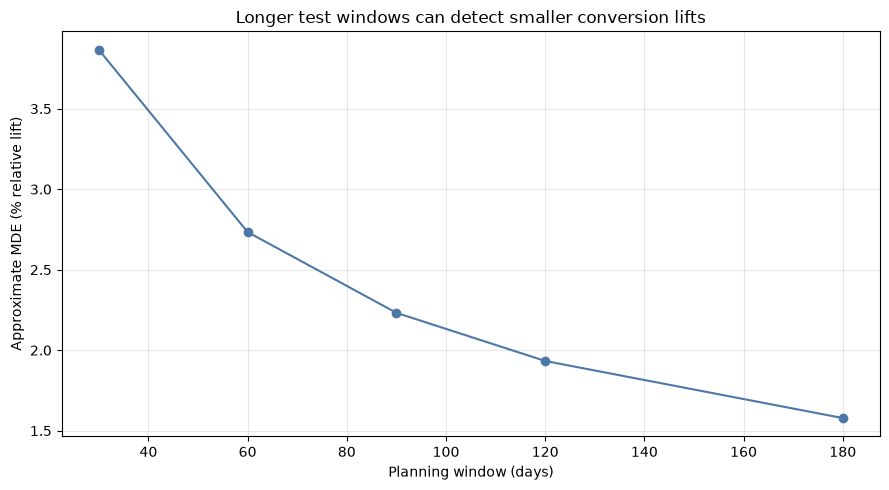

In [6]:
fig, ax = plt.subplots(figsize=(9,5))
ax.plot(windows["prospective_days"], windows["mde_relative"]*100, marker="o", color="#4C78A8")
ax.set(title="Longer test windows can detect smaller conversion lifts", xlabel="Planning window (days)", ylabel="Approximate MDE (% relative lift)")
ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "power_scenarios.png", dpi=180, bbox_inches="tight"); plt.show()

## What This Plan Can and Cannot Support

The calculations use 80% power, a two-sided 5% significance threshold and a 50/50 traffic split. They are suitable for initial planning, not final experiment approval.

The baseline comes from observational history and may change. The monthly dataset cannot reveal weekday patterns, novelty effects, ramp-up, contamination or attribution lag. Calendar estimates therefore describe possible traffic capacity, not promised delivery dates.

Before launch, the team should choose the smallest lift worth acting on, confirm eligible traffic and gross-margin economics, and recalculate power at the actual randomisation unit. The test plan should also define the primary metric, stopping rule and treatment of secondary metrics in advance. Random assignment, exposure logging, sample-ratio checks and intention-to-treat analysis remain essential.